In [1]:
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')

### Sampling from categorical distributions with `sample_proportions` ###

According to the CDC, about 10% of Americans 18 and over suffer from a depressive illness in any given year. [[source](https://www.cdc.gov/workplacehealthpromotion/health-strategies/depression/index.html)]

In [2]:
# Probability distribution
distribution_in_pop = make_array(0.9, 0.1)
distribution_in_pop

array([ 0.9,  0.1])

Suppose you have a group of 100 people. Let's simulate how many might suffer from a depressive illness, assuming we can treat each person as if they were drawn randomly from the population of US adults (a dubious assumption).

In [3]:
# Empirical distribution size 10
distribution_in_sample = sample_proportions(10, distribution_in_pop)
distribution_in_sample

array([ 0.9,  0.1])

In [4]:
# Empirical distribution size 1000
distribution_in_sample = sample_proportions(1000, distribution_in_pop)
distribution_in_sample

array([ 0.914,  0.086])

In [5]:
# Accessing a particular item
distribution_in_sample.item(0)

0.914

# Practice

A box contains 3 white balls, 4 black balls, and 1 green ball. You reach in and draw a ball three separate times, replacing the ball you drew before each draw (so the sample_proportions are the same for each draw). Call this procedure of drawing three balls one experiment.

Write a function that simulates this experiment and returns the statistic "number of green balls drawn".

In [21]:
def num_green():
    
    # prob_dist is probabily of green ball, probability of not green ball
    prob_dist = make_array(1/8,7/8)
    sample_dist = sample_proportions(3, prob_dist)
    number_green = sample_dist.item(0)
    return number_green

Use the num_green function to simulate the experiment 10,000 times to visualize the distribution of the "number of green balls drawn" statistic.

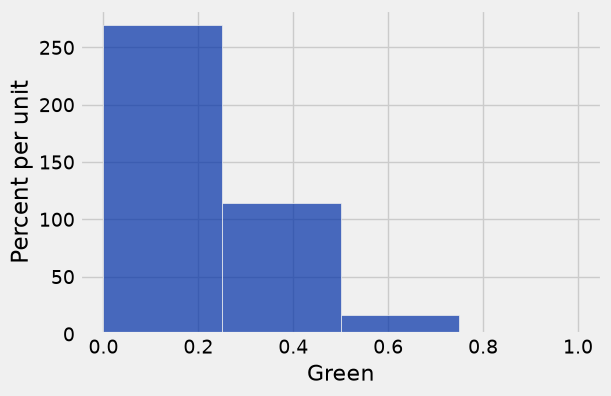

In [34]:
outcomes = make_array()
for _ in range(10000):
    green_experiment = num_green()
    outcomes = np.append(outcomes, green_experiment)

outcomes_tbl = Table().with_column("Green", outcomes)
outcomes_tbl.hist(bins = 4)

## Swain vs. Alabama ##

In 1962, a Black man named Robert Swain was convicted of murder in Talladega Country.

At that time, 26% of residents eligible for jury duty were Black.

Of the 100 jurors selected for Swain's trial, only 8 were Black.

Null Hypothesis: The jury selection was uniform and random. Pure random chance is sufficient to explain the observation (8% Black jurors).

Strategy for exploring the null hypothesis
1. Use sample_proportions to write a function that creates 100-person jury assuming 26% of the population is Black. The function should return the *number* of people on the jury identifying as Black.
2. Use a for loop simulate this statistic for 10,000 juries. Store all the outcomes in an array.
3. Create a single column table containing the outcomes in the array.
4. Visualize the outcomes with a histogram.

In [36]:
# Step 1: Simulate one experiment
def talladega_jurors():
    juror_pop_dist = make_array(.26,.74)
    juror_sample = sample_proportions(100, juror_pop_dist)
    num_black_jurors = 100 * juror_sample.item(0)
    return num_black_jurors

In [48]:
talladega_jurors()

32.0

In [53]:
# Step 2: Simulate many experiments
outcomes_arr = make_array()
for _ in range(10000):
    sim_jury = talladega_jurors()
    outcomes_arr = np.append(outcomes_arr, sim_jury)

print(outcomes_arr)

[ 33.  22.  26. ...,  32.  25.  29.]


In [56]:
# Step 3: Create a table of outcomes
jury_tbl = Table().with_column('Num Black Jurors', outcomes_arr)
jury_tbl.show(10)

Num Black Jurors
33
22
26
20
26
28
25
19
24
20


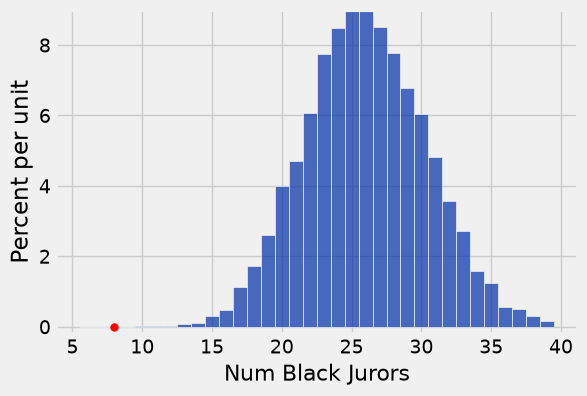

In [59]:
# Step 4 Visualize outcomes (already done)

jury_tbl.hist(bins=np.arange(5.5,40.))

# Plotting details; ignore this code
plots.ylim(-0.002, 0.09)
plots.scatter(8, 0, color='red', s=30);